# **Main Code**

**Importing necessary libraries**

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.regime_switching.markov_switching import MarkovSwitching

**Dataset utilised in paper: to check results**

In [ ]:
#data_path = "/Users/utente/Desktop/Thesis/Thesis/src/data.xlsx"
#data = pd.read_excel(data_path, header=None)

**Read datasets**

In [258]:
file_path = "/Users/utente/Desktop/Thesis/Thesis/src/Thesis_Dataset.xlsx"
dataset = pd.read_excel(file_path)

rf_path = "/Users/utente/Desktop/Thesis/Thesis/src/Rf.xlsx"
rf = pd.read_excel(rf_path)

**Filter datasets to include data from July 1969 onward**

In [259]:
# Filter the dataset for all rows where the Date is greater than or equal to July 1969
dataset = dataset[dataset['Date'] >= '1969-07']
rf = rf[rf['Date'] >= '1969-07']
rf = rf.drop(rf.index[-1]) #exclude last observation to align the datasets
rf = rf.iloc[:, [0, -1]] #keep risk-free rate column as it is the information we are interested in
print(dataset.shape)
print(rf.shape)

(663, 50)
(663, 2)


Missing data are indicated by -99.99 or -999.

Check presence in our data.

In [260]:
# Identify missing data values (-99.99 and -999) in the dataset
missing_data_counts = (dataset == -99.99).sum() + (dataset == -999).sum()

# Display columns with missing data counts
missing_data_present = missing_data_counts[missing_data_counts > 0]

# If you want to check the total number of such missing values in the dataset:
total_missing_data = missing_data_counts.sum()
print(f"\nTotal missing data points in the dataset: {total_missing_data}")


Total missing data points in the dataset: 0


#### **Merge Datasets and obtain returns in excess of the risk-free rate**

In [261]:
# 1. Merge on the 'Date' column
df = pd.merge(dataset, rf, on='Date', how='inner')

# 2. Identify all industry columns (49 columns).
#    We'll treat every column except 'Date' and 'RF' as an industry column.
industry_cols = [col for col in df.columns if col not in ['Date', 'RF']]

# 3. Subtract the risk-free rate from each industry column
for col in industry_cols:
    df[col] = df[col] - df['RF']

# 4. Drop RF column
df.drop(columns='RF', inplace=True)    

# 5. The final DataFrame 'merged_df' now has:
#    - Date
#    - 49 columns with monthly EXCESS returns
df.head()


,Date,Agric,Food,Soda,Beer,Smoke,Toys,Fun,Books,Hshld,...,Boxes,Trans,Whlsl,Rtail,Meals,Banks,Insur,RlEst,Fin,Other
0,1969-07,-8.85,-7.45,-4.06,-2.63,-5.27,-8.40,-10.68,-11.60,-3.96,...,-3.68,-13.03,-10.62,-8.72,-10.46,-7.13,-10.71,-13.27,-9.58,-15.17
1,1969-08,3.73,4.02,4.94,6.13,3.49,5.92,11.06,9.29,4.27,...,5.58,5.09,5.88,7.71,8.48,12.26,8.30,14.56,8.39,7.88
2,1969-09,0.97,-1.20,4.66,-1.53,3.50,1.51,-0.05,-1.23,-1.14,...,0.61,-2.18,-0.41,-1.37,-1.97,-3.56,6.46,-4.41,-3.16,-7.29
3,1969-10,16.35,7.37,6.24,11.04,11.82,5.68,12.97,6.99,5.81,...,2.90,4.29,10.65,5.65,8.43,10.11,5.11,3.94,9.71,3.10
4,1969-11,-2.39,-1.18,-5.43,-3.35,0.09,-8.85,-3.79,-4.49,-2.94,...,-2.50,-8.43,-7.35,-4.60,-2.42,-9.51,-5.42,-6.75,-6.43,-2.77


#### **Markov Switching Factor Model**

In [71]:
class MarkovSwitchingFactorModel:
    """
    Two-state Markov switching factor model.
    """
    
    def __init__(self, 
                 N: int, 
                 r_1: int, 
                 r_2: int, 
                 P: np.ndarray,
                 factor_dynamics="AR1",
                 factor_params_1=None,
                 factor_params_2=None):
        
        self.N = N
        self.r_1 = r_1
        self.r_2 = r_2

        assert P.shape == (2,2), "Transition matrix must be 2x2."
        assert np.allclose(P.sum(axis=1), 1.0), "Rows of P must sum to 1."
        self.P = P

        self.factor_dynamics = factor_dynamics
        self.factor_params_1 = factor_params_1 if factor_params_1 is not None else {}
        self.factor_params_2 = factor_params_2 if factor_params_2 is not None else {}

        # Parameters to be estimated
        self.Lambda_1 = None
        self.Lambda_2 = None
        self.Sigma_e1 = None
        self.Sigma_e2 = None
        self.Chol_e1 = None
        self.Chol_e2 = None

    def fit(self, X: np.ndarray, max_iter=100, tol=1e-5):
        # Placeholder for fitting the model to real data
        # Here you will implement:
        # - State inference (forward-backward)
        # - Factor estimation (Kalman filter/PCA)
        # - Parameter updates (EM steps)
        
        # Ensure data is N x T
        if X.shape[0] != self.N:
            if X.shape[1] == self.N:
                X = X.T
            else:
                raise ValueError("Data dimensions do not match N.")
        
        # Initialize parameters if needed
        if self.Lambda_1 is None:
            self.Lambda_1 = np.random.randn(self.N, self.r_1) * 0.01
        if self.Lambda_2 is None:
            self.Lambda_2 = np.random.randn(self.N, self.r_2) * 0.01
        if self.Sigma_e1 is None:
            self.Sigma_e1 = np.eye(self.N)
        if self.Sigma_e2 is None:
            self.Sigma_e2 = np.eye(self.N)
        
        self.Chol_e1 = np.linalg.cholesky(self.Sigma_e1)
        self.Chol_e2 = np.linalg.cholesky(self.Sigma_e2)
        
        # Stub: EM iteration
        for iteration in range(max_iter):
            # E-step: Infer states and factors (not implemented)
            # M-step: Update parameters (not implemented)
            
            # Check for convergence (not implemented)
            pass

    def simulate_states(self, T: int, s0: int = 1):
        states = np.zeros(T, dtype=int)
        states[0] = s0
        for t in range(1, T):
            current_state = states[t-1] - 1
            states[t] = np.random.choice([1, 2], p=self.P[current_state,:])
        return states

    def simulate_factors(self, T: int, states: np.ndarray):
        f_1t = np.full((self.r_1, T), np.nan)
        f_2t = np.full((self.r_2, T), np.nan)

        phi_1 = self.factor_params_1.get("phi", 0.0) if self.factor_dynamics == "AR1" else 0.0
        phi_2 = self.factor_params_2.get("phi", 0.0) if self.factor_dynamics == "AR1" else 0.0

        if self.r_1 > 0:
            f_1_current = np.zeros(self.r_1)
        if self.r_2 > 0:
            f_2_current = np.zeros(self.r_2)

        for t in range(T):
            st = states[t]
            if st == 1 and self.r_1 > 0:
                eps = np.random.randn(self.r_1)
                f_1_current = phi_1 * f_1_current + eps
                f_1t[:, t] = f_1_current
            elif st == 2 and self.r_2 > 0:
                eps = np.random.randn(self.r_2)
                f_2_current = phi_2 * f_2_current + eps
                f_2t[:, t] = f_2_current
        return f_1t, f_2t

    def simulate_data(self, T: int, s0: int = 1):
        if self.Lambda_1 is None or self.Lambda_2 is None:
            self.Lambda_1 = np.random.randn(self.N, self.r_1) * 0.1
            self.Lambda_2 = np.random.randn(self.N, self.r_2) * 0.1
        if self.Sigma_e1 is None or self.Sigma_e2 is None:
            self.Sigma_e1 = np.eye(self.N)
            self.Sigma_e2 = np.eye(self.N)
        if self.Chol_e1 is None:
            self.Chol_e1 = np.linalg.cholesky(self.Sigma_e1)
        if self.Chol_e2 is None:
            self.Chol_e2 = np.linalg.cholesky(self.Sigma_e2)

        states = self.simulate_states(T, s0=s0)
        f_1t, f_2t = self.simulate_factors(T, states)
        
        x = np.zeros((self.N, T))
        for t in range(T):
            st = states[t]
            nu_t = np.random.randn(self.N)
            if st == 1:
                if self.r_1 > 0:
                    x[:, t] = self.Lambda_1 @ f_1t[:, t] + self.Chol_e1 @ nu_t
                else:
                    x[:, t] = self.Chol_e1 @ nu_t
            else:
                if self.r_2 > 0:
                    x[:, t] = self.Lambda_2 @ f_2t[:, t] + self.Chol_e2 @ nu_t
                else:
                    x[:, t] = self.Chol_e2 @ nu_t
        return x, states, f_1t, f_2t


#### **Demeaning of returns**

Centering the data will be important for later steps, thus, we proceed with demeaning the returns.

This operation, effectively, makes it so that our unconditional returns are equal to 0.

In [262]:
# Step 1: Separate the 'Date' column
dates = df['Date']
returns_data = df.loc[:, df.columns != 'Date']

# Step 2: Compute the mean of each portfolio
portfolio_means = returns_data.mean(axis=0)

# Step 3: Demean the returns
demeaned_returns = returns_data.subtract(portfolio_means, axis=1)

# Step 4: Verify the unconditional mean is zero
demeaned_means = demeaned_returns.mean(axis=0)
# Check that the absolute values are close to zero
print((demeaned_means.abs() < 1e-12).all())  # Should return True

# Step 5: Save back the returns dataset as "VWExcessRet"
VWExcessRet = demeaned_returns

VWExcessRet.columns = range(VWExcessRet.shape[1])

True


#### **Implement estimators to obtain the optimal number of latent factors**

##### **Eigenvalue Ratio estimator**

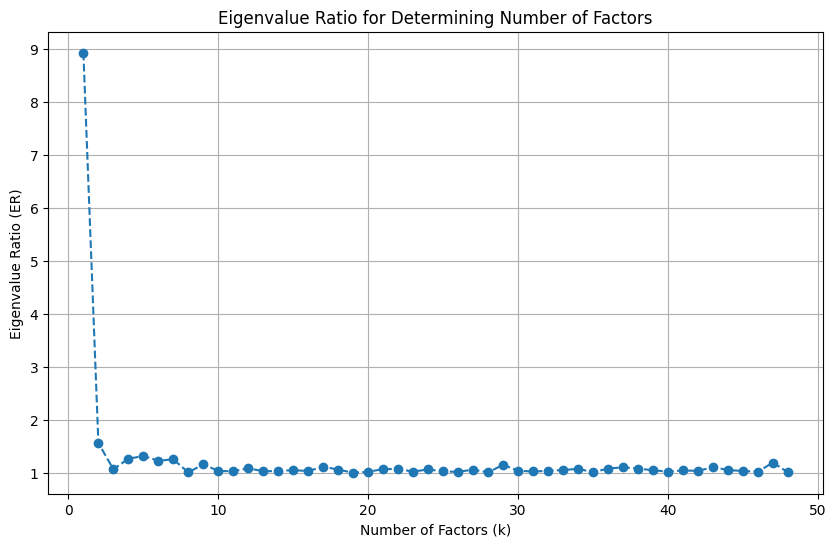

Optimal number of factors: 1


In [122]:
# Step 1: Compute the covariance matrix of the dataset
cov_matrix= np.cov(VWExcessRet, rowvar=False)

# Step 2: Compute the eigenvalues of the covariance matrix
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Step 3: Sort eigenvalues in descending order
eigenvalues = np.sort(eigenvalues)[::-1]

# Step 4: Calculate the Eigenvalue Ratio (ER) for each k
er_ratios = [eigenvalues[i] / eigenvalues[i + 1] for i in range(len(eigenvalues) - 1)]

# Step 5: Find the optimal number of factors by finding the maximum ratio
optimal_num_factors = np.argmax(er_ratios) + 1

# Step 6: Plot the eigenvalue ratios for visualization
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(er_ratios) + 1), er_ratios, marker='o', linestyle='--')
plt.xlabel('Number of Factors (k)')
plt.ylabel('Eigenvalue Ratio (ER)')
plt.title('Eigenvalue Ratio for Determining Number of Factors')
plt.grid(True)
plt.show()

print(f"Optimal number of factors: {optimal_num_factors}")

##### **Growth Ratio estimator**

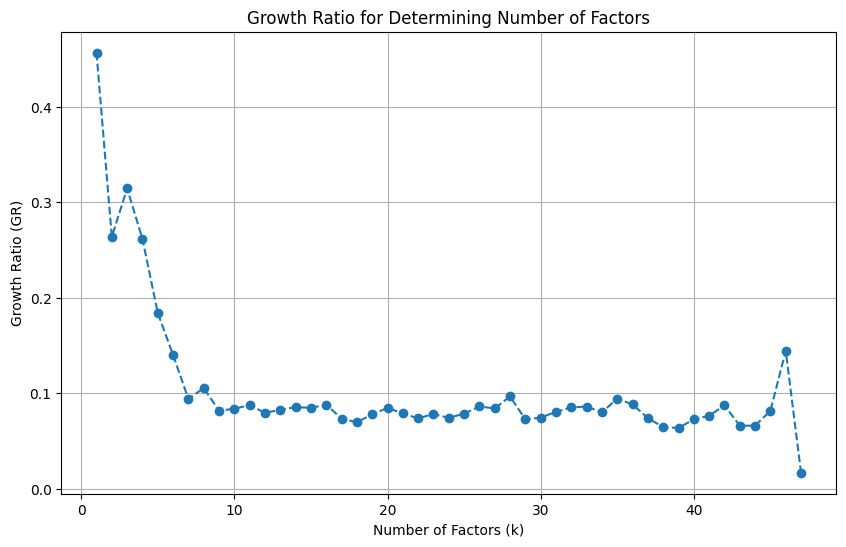

Optimal number of factors (Growth Ratio): 1


In [123]:
# Step 1: Calculate the Growth Ratio (GR) for each k
V = [np.sum(eigenvalues[i+1:]**2) / (len(eigenvalues) - (i + 1)) for i in range(len(eigenvalues) - 1)]
gr_ratios = [np.log(V[k]) - np.log(V[k + 1]) for k in range(len(V) - 1)]

# Step 2: Find the optimal number of factors by finding the maximum growth ratio
optimal_num_factors_gr = np.argmax(gr_ratios) + 1

# Step 3: Plot the growth ratios for visualization
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(gr_ratios) + 1), gr_ratios, marker='o', linestyle='--')
plt.xlabel('Number of Factors (k)')
plt.ylabel('Growth Ratio (GR)')
plt.title('Growth Ratio for Determining Number of Factors')
plt.grid(True)
plt.show()

print(f"Optimal number of factors (Growth Ratio): {optimal_num_factors_gr}")

#### **Number of factors**

In [263]:
# maximum number of factors
rmax = 10

# Preallocate ER and GR
ER = np.zeros((rmax, 1))
GR = np.zeros((rmax, 1))

# Get covariance matrix 
Sigma = np.cov(VWExcessRet, rowvar=False)

# Get eigenvalues of covariance matrix
vals, _ = np.linalg.eigh(Sigma)

# Sort eigenvalues in descending order
vals_sorted = np.sort(vals)[::-1]

# Take top (rmax+1) eigenvalues
DAH = vals_sorted[:rmax+1]

# Compute ER and GR
for j in range(rmax):
    ER[j, 0] = DAH[j] / DAH[j+1]
    GR[j, 0] = np.log(1 + DAH[j]) / np.log(1 + DAH[j+1])

# Find index of maximum GR
max_val = np.max(GR[1:, 0])  # ignoring first row, i.e. index 0
indices = np.where(GR[:, 0] == max_val)[0]  # returns 0-based indices
r = indices[0] + 1 # r = 2

r = 2

##### **Estimation of factors and loadings**

In [264]:
# From previous estimation, we know that the number of factors is 2
r = 2

# Get top eigenvalues and eigenvectors of covariance matrix calculated before
vals, vecs = np.linalg.eigh(Sigma)

# Sort eigenvalues (and corresponding vectors) in descending order
idx = np.argsort(vals)[::-1]
vals = vals[idx]
vecs = vecs[:, idx]

# Extract the top-r eigenvalues/vectors
vals_r = vals[:r]                 
vecs_r = vecs[:, :r] 

# Calculation of factor scores ghat
D_inv_sqrt = np.diag(1.0 / np.sqrt(vals_r))
ghat = (D_inv_sqrt @ vecs_r.T @ VWExcessRet.T).T

# Calculation of loadings Ahat
D_sqrt = np.diag(np.sqrt(vals_r)) 
Ahat = vecs_r @ D_sqrt  

# Reconstructed data
chihat = (Ahat @ ghat.T).T

# Reconstructed data using only 2 factors
chihat1 = (vecs_r @ vecs_r.T @ VWExcessRet.T).T

# Calculation of residuals
ehat = VWExcessRet-chihat

## **EM algorithm**

#### **Initialization of EM parameters**

In [265]:
# EM parameters
kmax = 100
thresh = 1e-6
eps = [0.49, 0.1] 
min_eta = 1e-50

#### **Pre-allocate parameters**

In [266]:
T, N = VWExcessRet.shape

# Create arrays of zeros of correct dimensions to be filled in the estimation phase

Phat       = np.zeros((2, 2, kmax+1))
rhohat     = np.zeros((2*2, kmax+1))   
Bhat       = np.zeros((N, r, 2, kmax+1))
Sigmaehat  = np.zeros((N, N, 2, kmax+1))
etahat     = np.zeros((T, 2, kmax+1))
llik       = np.zeros((kmax+1, 1))    

xit1       = np.zeros((T, 2, kmax+1))
xitt       = np.zeros((T, 2, kmax+1))
xitT       = np.zeros((T, 2, kmax+1))
xitT2      = np.zeros((T, 2*2, kmax+1))  

fhat       = np.zeros((T, r))

Define function which we will need at later step.

In [267]:
def ML_vec(X):
    """
    Reshape a 2D NumPy array X of shape (m, n) into a 1D or 2D column vector.

    Parameters:
    X : numpy.ndarray
        2D array of shape (m, n).

    Returns:
    x : numpy.ndarray
        1D array of length m*n if we go for standard NumPy convention,
        or a 2D array of shape (m*n, 1) 
    """
    m, n = X.shape
    # Option A: standard NumPy approach: shape (m*n, )
    x = X.reshape(m*n,)
    
    # Option B: if you really want a (m*n, 1) shape:
    # x = X.reshape(m*n, 1)
    
    return x

In [268]:
# Initialize parameters

# Assign Bhat
Bhat[:, :, 0, 0] = Ahat
Bhat[:, :, 1, 0] = Ahat

# Assign Sigmaehat
Sigma_e = np.diag(np.diag(np.cov(ehat, rowvar=False)))  # (N,N)
Sigmaehat[:, :, 0, 0] = Sigma_e
Sigmaehat[:, :, 1, 0] = Sigma_e

# Assign first Phat
Phat[:, :, 0] = np.array([
    [0.5 + eps[0],       1 - 0.5 - eps[0]],
    [1 - 0.5 - eps[1],   0.5 + eps[1]]
])

# Assign rhohat
rhohat[:, 0] = ML_vec(Phat[:, :, 0])

xi00 = np.array([1, 0])

In [273]:
# Ensure VWExcessRet is a NumPy array
x = VWExcessRet.to_numpy() if isinstance(VWExcessRet, pd.DataFrame) else VWExcessRet

print(type(x))        # Should print <class 'numpy.ndarray'>
print(x.shape)        # Confirm the dimensions are (T, N)

g = ghat.to_numpy()
print(type(g))        # Should print <class 'numpy.ndarray'>
print(g.shape)        # Confirm the dimensions are (T, r)

<class 'numpy.ndarray'>
(663, 49)
<class 'numpy.ndarray'>
(663, 2)


In [289]:
# Initialize state
xit1[0, :, 0] = (Phat[:, :, 0].T @ xi00).T

Ec = np.eye(2)

# Compute etahat for t=1:T, j=1:2
for t in range(T):
    for j in range(2):
        B_all = np.hstack([Bhat[:, :, 0, 0], Bhat[:, :, 1, 0]]) 

        diff = x[t, :] - np.kron(Ec[j, :], g[t, :]) @ B_all.T  

        c1 = (2 * np.pi) ** (-N / 2)
        c2 = np.linalg.det(Sigmaehat[:, :, j, 0]) ** (-0.5)

        exponent = diff @ np.linalg.inv(Sigmaehat[:, :, j, 0]) @ diff
        val = c1 * c2 * np.exp(-0.5 * exponent)

        if val == 0:
            val = min_eta

        etahat[t, j, 0] = val

# EM iterations
for k in range(1, kmax + 1):
    print(f"EM iteration {k}")
    llik[k, 0] = np.sum(np.log(etahat[:, 0, k-1] + etahat[:, 1, k-1]))
    print(f"--llik {llik[k, 0]}")

# Expectation (E) step

# Hamilton Filter
#for t in range(T):
#    xitt[t, :, k] = (etahat[t, :, k] * xit1[t, :, k]) / (np.ones(2) @ (etahat[t, :, k] * xit1[t, :, k]).T)
 #   if t < T - 1:
 #       xit1[t + 1, :, k] = (Phat[:, :, k].T @ xitt[t, :, k]).T

EM iteration 1
--llik -89756.87740949457
EM iteration 2
--llik -inf
EM iteration 3
--llik -inf
EM iteration 4
--llik -inf
EM iteration 5
--llik -inf
EM iteration 6
--llik -inf
EM iteration 7
--llik -inf
EM iteration 8
--llik -inf
EM iteration 9
--llik -inf
EM iteration 10
--llik -inf
EM iteration 11
--llik -inf
EM iteration 12
--llik -inf
EM iteration 13
--llik -inf
EM iteration 14
--llik -inf
EM iteration 15
--llik -inf
EM iteration 16
--llik -inf
EM iteration 17
--llik -inf
EM iteration 18
--llik -inf
EM iteration 19
--llik -inf
EM iteration 20
--llik -inf
EM iteration 21
--llik -inf
EM iteration 22
--llik -inf
EM iteration 23
--llik -inf
EM iteration 24
--llik -inf
EM iteration 25
--llik -inf
EM iteration 26
--llik -inf
EM iteration 27
--llik -inf
EM iteration 28
--llik -inf
EM iteration 29
--llik -inf
EM iteration 30
--llik -inf
EM iteration 31
--llik -inf
EM iteration 32
--llik -inf
EM iteration 33
--llik -inf
EM iteration 34
--llik -inf
EM iteration 35
--llik -inf
EM iteration 36

/var/folders/20/jt1tkq213g3frrgs2z5n6zgc0000gn/T/ipykernel_74980/794000843.py:27: RuntimeWarning: divide by zero encountered in log
  llik[k, 0] = np.sum(np.log(etahat[:, 0, k-1] + etahat[:, 1, k-1]))
